# 08 · Pretrained fastText + BiGRU + CRF + case feature

One model with everything that should help, trained on the cleaned train file from notebook 06:
- **data:** `train_v2.parquet` (notebook 06): the whole uk dataset cleaned and deduplicated, plus 20% ru;
- **embeddings:** pretrained fastText `cc.uk.300` (Common Crawl + Wikipedia, 300d), **with case**, fine-tuned at a
  lower learning rate. Its subword n-grams give a vector to every word, also unseen town names (`Фастів`,
  `Баришівка`), so the model is word-level and needs no BPE;
- **case feature:** the 5 case classes of notebook 07, embedded and concatenated to the word vector;
- **model:** 2-layer BiGRU → emissions → **CRF** (self-written, notebook 07), decoded with Viterbi.

**Result of the first run** (`taras-bigru2-word-fasttext-crf-case-data2-uk500k-ru100k`): gold F1 **0.765** (P 0.633,
R 0.969), public LB **0.598**, the best so far (notebook 05: 0.597 / 0.537). The best epoch by val F1 was 1 of 4. Recall
is almost saturated; the false positives are countries (`Україні`), bare `Київ` / `Києва` from signatures and
organisation names, and an unlabeled station schedule. The LB gain (+0.06) is much smaller than the gold gain (+0.17).

**Splits** (the names used in the code):

| Name | Source | Size | Labels | Domain | Used for |
|---|---|---|---|---|---|
| `train` | `train_v2.parquet`, `is_valid == 0` | 600k sentences (uk 500k, ru 100k) | silver (automatic) | news sentences | training |
| `val` | `train_v2.parquet`, `is_valid == 1` | 10k uk sentences | silver | news sentences | picks the best epoch, early stopping |
| `gold` | `labeling_sample.csv` | 26 posts | gold (by hand) | Telegram posts, like test | our estimate of the LB, reported as "CV" |
| `test` | `test.csv` | 477 posts | none | Telegram posts | the Kaggle submission |

- `val` and `gold` are both scored after every epoch, but only `val` chooses the checkpoint: choosing it on 26 gold
  texts would overfit them.
- `val` is cleaned like `train`, so `val_f1` is not comparable with notebooks 02–07; `gold_f1` is.
- The team's results log `experiments.csv` keeps its column names: `cv_f1` is gold F1, `es_f1` is val F1.

**How to run:** on Colab with a GPU, top to bottom. Put `train_v2.parquet` (output of notebook 06) into
`MyDrive/dl-a3-artifacts/` first and mount Drive. The first run downloads fastText (4.5 GB), builds the embedding
matrix for our vocabulary and caches it next to the data, so later runs skip that. `QUICK_RUN=1` checks the code on
CPU with a tiny fastText model trained on the quick-run texts instead of the real one.

## 0. Shared code
Taken from the shared section 0 of notebook 02 (tokenizer, metric, output format), with two differences from
notebook 08 on: the splits are called `train / val / gold / test`, and code this notebook doesn't call is left out
(the softmax tagger, BPE alignment, W&B and the Kaggle CLI).

### 0.0 Setup
- **Colab:** no Kaggle or W&B keys are needed. The cell mounts Google Drive; everything is read from and written
  to `MyDrive/dl-a3-artifacts` (the team's shared folder, so it survives the VM reset):
  - `train_v2.parquet` (notebook 06) in the folder itself;
  - `labeling_sample.csv` and `test.csv` in its `data/` subfolder (upload them once);
  - all run outputs, including `submission.csv`, which is uploaded to Kaggle by hand.
- **Locally:** the data is read from `data/raw/`, outputs go to `artifacts/` (git-ignored).
- `QUICK_RUN=1` (environment variable) trains on a small subset for one epoch, to check the code in a few minutes.

In [1]:
import importlib.util
import os
import shutil
import subprocess
import sys
from pathlib import Path

DATA_FILES = ["labeling_sample.csv", "test.csv"]  # train and val come from train_v2.parquet (notebook 06)
IN_COLAB = Path("/content").exists()
QUICK_RUN = os.environ.get("QUICK_RUN") == "1"


def install_missing(packages: dict[str, str]) -> None:
    """{import name: pip name}; installs only what is missing."""
    missing = [pip for module, pip in packages.items() if importlib.util.find_spec(module) is None]
    if missing:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)


install_missing({"lightning": "lightning"})
if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    ARTIFACTS = Path("/content/drive/MyDrive/dl-a3-artifacts")  # the team's shared folder; mounted above
    RAW = ARTIFACTS / "data"  # upload labeling_sample.csv and test.csv here once
else:
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    RAW = ROOT / "data/raw" if (ROOT / "data/raw").exists() else ROOT / "data"
    ARTIFACTS = ROOT / "artifacts"
missing = [name for name in DATA_FILES if not (RAW / name).exists()]
assert not missing, f"put {missing} into {RAW}"
if QUICK_RUN:
    ARTIFACTS = ARTIFACTS / "quick_run"
ARTIFACTS.mkdir(parents=True, exist_ok=True)
print(f"data: {RAW} | outputs: {ARTIFACTS} | quick run: {QUICK_RUN}")

Mounted at /content/drive
data: /content/drive/MyDrive/dl-a3-artifacts/data | outputs: /content/drive/MyDrive/dl-a3-artifacts | quick run: False


### 0.1 Tokenizer, span ↔ BIO, competition metric
Every training notebook uses the same code. Each token keeps its character offsets, so predicted tags can be turned
back into **exact substrings** of the text, which is what the metric compares. Punctuation becomes its own token
(`Київ,` → `Київ` `,`), while inner hyphens and apostrophes stay inside the word (`Івано-Франківськ`,
`Слов'янськ`).

In [2]:
import ast
import re
import unicodedata
import string
from collections import Counter
from dataclasses import dataclass
from typing import List, Sequence

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

TOKEN_RE = re.compile(r"\w+(?:[-'’ʼ`]\w+)*|[^\w\s]")


@dataclass(frozen=True)
class Token:
    text: str
    start: int
    end: int  # exclusive


def word_tokenize(text: str) -> list[Token]:
    return [Token(m.group(), m.start(), m.end()) for m in TOKEN_RE.finditer(text)]


def parse_markers(value) -> list[tuple[int, int]]:
    """`loc_markers` as stored in the CSV ("[(0, 4), (10, 15)]") -> [(start, end), ...], end exclusive."""
    if not isinstance(value, str):
        return []
    return [(int(a), int(b)) for a, b in ast.literal_eval(value.strip() or "[]")]


def spans_to_bio(tokens: Sequence[Token], spans) -> list[str]:
    """Every token that overlaps a span is labelled: the first one B-LOC, the rest I-LOC."""
    labels = ["O"] * len(tokens)
    for left, right in sorted(spans):
        first = True
        for i, tok in enumerate(tokens):
            if tok.start < right and tok.end > left:
                labels[i] = "B-LOC" if first else "I-LOC"
                first = False
    return labels


def bio_to_spans(tokens: Sequence[Token], tags: Sequence[str]) -> list[tuple[int, int]]:
    """Merge BIO tags into character spans; an I-LOC without an open entity starts a new one."""
    spans, current = [], None
    for tok, tag in zip(tokens, tags):
        if tag == "B-LOC" or (tag == "I-LOC" and current is None):
            if current is not None:
                spans.append(tuple(current))
            current = [tok.start, tok.end]
        elif tag == "I-LOC":
            current[1] = tok.end
        else:
            if current is not None:
                spans.append(tuple(current))
            current = None
    if current is not None:
        spans.append(tuple(current))
    return spans


def spans_to_strings(text: str, spans) -> list[str]:
    """Cut location strings out of the original text (deduplicated, order kept)."""
    return list(dict.fromkeys(s for s in (text[a:b].strip() for a, b in spans) if s))

`hard_processing` and `comp_metric` below are copied **verbatim** from the competition page. Do not "fix" them.

In [3]:
def hard_processing(text):
    text = re.sub(r"[{re.escape(string.punctuation)}]", "", text)
    text = re.sub(r'\d', '', text)
    text = re.sub(r'\b\w\b\s?', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text.lower()


def comp_metric(y_true: List[List[str]], y_pred: List[List[str]]):
    assert len(y_true) == len(y_pred)
    tp, fp, fn, p,  = 0.0, 0.0, 0.0, 0.0

    for y_true_sample, y_pred_sample in zip(y_true, y_pred):
        y_true_sample = set([hard_processing(s) for s in y_true_sample])
        y_pred_sample = set([hard_processing(s) for s in y_pred_sample])

        tp += len(y_true_sample & y_pred_sample)
        fp += len(y_pred_sample - y_true_sample)
        fn += len(y_true_sample - y_pred_sample)
        p += len(y_true_sample)

    if tp + fp == 0:
        if p == 0:
            precision = 1.0
        else:
            precision = 0.0
    else:
        precision = tp/(tp + fp)

    if tp + fn == 0:
        if p == 0:
            recall = 1.0
        else:
            recall = 0.0
    else:
        recall = tp/(tp + fn)

    if precision + recall == 0:
        f1 = 0
    else:
        f1 = 2 * precision * recall / (precision + recall)
    return round(f1, 8)

Complementary metrics (notebook 01, section 8). They count exactly like `comp_metric`, plus:

In [4]:
def precision_recall(y_true, y_pred) -> tuple[float, float]:
    tp = fp = fn = 0
    for true_strings, pred_strings in zip(y_true, y_pred):
        t, p = {hard_processing(s) for s in true_strings}, {hard_processing(s) for s in pred_strings}
        tp, fp, fn = tp + len(t & p), fp + len(p - t), fn + len(t - p)
    precision = tp / (tp + fp) if tp + fp else float(tp + fn == 0)
    recall = tp / (tp + fn) if tp + fn else 1.0
    return precision, recall


def partial_match_f1(y_true, y_pred) -> float:
    """Boundary-tolerant F1: a location counts if it shares a normalized word with one on the other side."""
    words = lambda s: set(hard_processing(s).split())
    hit_p = n_p = hit_t = n_t = 0
    for true_strings, pred_strings in zip(y_true, y_pred):
        t_sets = [words(s) for s in {hard_processing(x) for x in true_strings}]
        p_sets = [words(s) for s in {hard_processing(x) for x in pred_strings}]
        n_p, n_t = n_p + len(p_sets), n_t + len(t_sets)
        hit_p += sum(any(p & t for t in t_sets) for p in p_sets)
        hit_t += sum(any(t & p for p in p_sets) for t in t_sets)
    precision, recall = (hit_p / n_p if n_p else 1.0), (hit_t / n_t if n_t else 1.0)
    return 2 * precision * recall / (precision + recall) if precision + recall else 0.0


def metric_report(y_true, y_pred) -> dict:
    precision, recall = precision_recall(y_true, y_pred)
    no_loc = [len(p) > 0 for t, p in zip(y_true, y_pred) if not t]
    with_loc = [(t, p) for t, p in zip(y_true, y_pred) if t]
    return {
        "f1": comp_metric(y_true, y_pred),
        "precision": precision,
        "recall": recall,
        "partial_f1": partial_match_f1(y_true, y_pred),
        "f1_texts_with_loc": comp_metric([t for t, _ in with_loc], [p for _, p in with_loc]),
        "fp_rate_texts_without_loc": float(np.mean(no_loc)) if no_loc else 0.0,
    }

### 0.2 Corpus
A `Corpus` holds one split: the texts, their word tokens (with character offsets, which decoding needs; train skips
them to save memory), the BIO tag ids per word and the true location strings (`locations`: gold for `gold`, silver for
`train` and `val`, none for `test`).

In [5]:
import json
import logging
import time
import warnings

import lightning as L
import torch
import torch.nn as nn
from lightning.pytorch.callbacks import EarlyStopping, ModelCheckpoint, TQDMProgressBar
from lightning.pytorch.loggers import CSVLogger
from lightning.pytorch.utilities import grad_norm
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from torch.utils.data import DataLoader, Dataset

warnings.filterwarnings("ignore", module="lightning")
logging.getLogger("lightning.pytorch").setLevel(logging.WARNING)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
LABELS = ["O", "B-LOC", "I-LOC"]
LABEL2ID = {label: i for i, label in enumerate(LABELS)}
ID2LABEL = dict(enumerate(LABELS))
PAD_TOKEN, UNK_TOKEN, PAD_ID, UNK_ID = "<pad>", "<unk>", 0, 1
print("device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")


class Corpus:
    def __init__(self, texts, spans=None, keep_tokens: bool = True):
        texts = [str(t) for t in texts]
        tokens = [word_tokenize(t) for t in texts]
        self.words = [[t.text for t in toks] for toks in tokens]
        self.tags = None if spans is None else [
            np.array([LABEL2ID[tag] for tag in spans_to_bio(toks, s)], dtype=np.int64) for toks, s in zip(tokens, spans)]
        self.locations = None if spans is None else [[t[a:b] for a, b in s] for t, s in zip(texts, spans)]
        self.texts, self.tokens = texts, (tokens if keep_tokens else None)

    def __len__(self) -> int:
        return len(self.words)


def decode(corpus: Corpus, probs: list[np.ndarray]) -> list[list[str]]:
    """Per-word tag probabilities -> argmax tag -> BIO -> character spans -> strings cut from the text."""
    tags = [[ID2LABEL[int(i)] for i in p.argmax(-1)] for p in probs]
    return [spans_to_strings(text, bio_to_spans(toks, t)) for text, toks, t in zip(corpus.texts, corpus.tokens, tags)]

device: cuda NVIDIA A100-SXM4-40GB


### 0.3 Run outputs and the results log
- `save_probs` / `load_probs` keep a run's per-word tag probabilities for `gold` and `test` (for ensembling);
  `write_submission` writes the Kaggle file.
- `show_report` prints a run's report with readable names.
- `ARTIFACTS/experiments.csv` holds one row per run: `run_name, owner, point, description, cv_f1, cv_p, cv_r, es_f1,
  lb_public, notes`. These are the team's column names, so `cv_*` are the gold scores and `es_f1` is val F1. Failed
  runs stay in. `log_result` replaces the run's row and keeps an LB score that is already there.

In [6]:
import pickle

RESULTS_LOG = ARTIFACTS / "experiments.csv"
LOG_COLUMNS = ["run_name", "owner", "point", "description", "cv_f1", "cv_p", "cv_r", "es_f1", "lb_public", "notes"]
REPORT_LABELS = {
    "gold_f1": "gold F1 (competition metric)",
    "gold_precision": "gold precision",
    "gold_recall": "gold recall",
    "gold_partial_f1": "gold partial-match F1 (one shared word is enough)",
    "gold_f1_texts_with_loc": "gold F1 on texts with a location",
    "gold_fp_rate_texts_without_loc": "gold: share of texts without a location that get a prediction",
    "val_f1": "val F1 (silver labels, picks the epoch)",
    "best_epoch": "best epoch (counted from 0)",
    "epochs_run": "epochs run",
    "vocab_size": "vocabulary size",
    "params": "parameters",
    "minutes": "training time, minutes",
}


def save_probs(probs, path: Path) -> None:
    with open(path, "wb") as f:
        pickle.dump([p.astype(np.float16) for p in probs], f)


def load_probs(run: str, split: str) -> list[np.ndarray]:
    """Per-word tag probabilities a run saved for `split` ("gold" or "test")."""
    with open(ARTIFACTS / run / f"{split}_probs.pkl", "rb") as f:
        return [p.astype(np.float32) for p in pickle.load(f)]


def write_submission(text_ids, locations, path: Path) -> None:
    pd.DataFrame({"text_id": text_ids,
                  "locations": [json.dumps(list(x), ensure_ascii=False) for x in locations]}).to_csv(path, index=False)


def show_report(report: dict) -> pd.DataFrame:
    rows = {label: round(report[key], 3) if isinstance(report[key], float) else report[key]
            for key, label in REPORT_LABELS.items()}
    return pd.Series(rows, dtype=object).to_frame(report["run_name"])


def read_log() -> pd.DataFrame:
    return pd.read_csv(RESULTS_LOG) if RESULTS_LOG.exists() else pd.DataFrame(columns=LOG_COLUMNS)


def log_result(cfg: dict, report: dict, lb_public: float | None = None, notes: str = "") -> pd.DataFrame:
    log = read_log()
    old = log[log.run_name == cfg["run_name"]]
    if lb_public is None and len(old):
        lb_public = old.lb_public.iloc[0]
    row = {"run_name": cfg["run_name"], "owner": cfg["owner"], "point": cfg["point"],
           "description": cfg.get("description", ""), "cv_f1": report["gold_f1"], "cv_p": report["gold_precision"],
           "cv_r": report["gold_recall"], "es_f1": report["val_f1"], "lb_public": lb_public, "notes": notes}
    others = log[log.run_name != cfg["run_name"]]
    log = pd.DataFrame([*others.to_dict("records"), row], columns=LOG_COLUMNS)  # no concat: no all-NA dtype warning
    if not QUICK_RUN:
        log.to_csv(RESULTS_LOG, index=False)
    return log

## 1. Data
- **train / val** come from `train_v2.parquet` (notebook 06): `is_valid == 0` is train (uk + ru), `is_valid == 1` is
  val (see the table at the top).
- **gold and test** come from the raw CSVs and are never changed.
- `TRAIN_ROWS` caps the train sentences per language (now uk 500k, ru 100k: a first, faster run). `val` is always
  all 10k rows. Set a language to `None` to use all of its rows.
- `QUICK_RUN` then samples 20k train and 2k val sentences.

In [7]:
TRAIN_CLEAN = ARTIFACTS / "train_v2.parquet"  # cleaned train + val, built by notebook 06
TRAIN_ROWS = {"uk": 500_000, "ru": 100_000}  # train sentences per language (random, fixed seed); None = all


def load_corpora() -> tuple[dict[str, Corpus], pd.DataFrame]:
    assert TRAIN_CLEAN.exists(), f"run notebook 06 and put train_v2.parquet into {ARTIFACTS}"
    df = pd.read_parquet(TRAIN_CLEAN)
    gold_df, test_df = pd.read_csv(RAW / "labeling_sample.csv"), pd.read_csv(RAW / "test.csv")
    train_df, val_df = df[df.is_valid == 0], df[df.is_valid == 1]
    train_df = pd.concat([g if TRAIN_ROWS.get(lang) is None else g.sample(min(TRAIN_ROWS[lang], len(g)), random_state=0)
                          for lang, g in train_df.groupby("lang")])
    if QUICK_RUN:
        train_df = train_df.sample(min(20_000, len(train_df)), random_state=0)
        val_df = val_df.sample(min(2_000, len(val_df)), random_state=0)
    print("train rows by language:", train_df.lang.value_counts().to_dict())
    corpora = {
        "train": Corpus(train_df.text, train_df.loc_markers.map(parse_markers), keep_tokens=False),
        "val": Corpus(val_df.text, val_df.loc_markers.map(parse_markers)),
        "gold": Corpus(gold_df.text, gold_df.loc_markers.map(parse_markers)),
        "test": Corpus(test_df.text),
    }
    return corpora, test_df


corpora, test_df = load_corpora()
print({name: len(c) for name, c in corpora.items()})

train rows by language: {'uk': 500000, 'ru': 100000}
{'train': 600000, 'val': 10000, 'gold': 26, 'test': 477}


## 2. fastText vocabulary and embeddings
- **Vocabulary** (`FastTextVocab`): the 200k most frequent train words seen at least twice, **case kept**, plus every
  word of `val`, `gold` and `test`. Those extra words get their vector from fastText's subword n-grams; no label is
  read, the vector is a function of the word alone.
- **Lookup normalization** (`normalize_word`, ids only; the text and the output strings keep the original chars):
  - apostrophe variants (`’ ʼ ‘ ´`) become `'`;
  - dash variants (`– — − ‑`) become `-`, so a spaced dash is one id in uk (mostly `-`, `–`), ru (`—`) and test (all
    three);
  - every emoji piece, bullet (`• ▪ ♦ · ►`) and invisible char (`U+FE0F`, ZWJ, ZWSP) becomes one `<emoji>` id; `№ ° ©`
    stay. Emoji are 3.1% of test tokens and almost absent from train, but train has a few hundred bullets and
    invisible chars, so the `<emoji>` row is trained (as `O`) instead of being a random n-gram vector per emoji.
- **Embedding matrix:** row `i` = `fastText.get_word_vector(itos[i])`; `<pad>` and `<unk>` are zeros. It initialises
  `nn.Embedding` and is fine-tuned at `emb_lr_mult` × the learning rate, so the pretrained geometry is kept.
- The `.bin` model needs about 7.5 GB of RAM while it is loaded. It is freed right after the matrix is built, and the
  matrix is cached in `ARTIFACTS/fasttext_v2.npz` (with the vocabulary, to check the cache matches).

In [8]:
import gc
import gzip
import urllib.request

install_missing({"fasttext": "fasttext"})
import fasttext  # noqa: E402

FASTTEXT_URL = "https://dl.fbaipublicfiles.com/fasttext/vectors-crawl/cc.uk.300.bin.gz"
FASTTEXT_BIN = Path("/content/cc.uk.300.bin") if IN_COLAB else ARTIFACTS / "cc.uk.300.bin"
EMB_CACHE = ARTIFACTS / "fasttext_v2.npz"
APOSTROPHES, DASHES = "’ʼ‘`′´", "–—―‒−‑‐"
CHAR_TABLE = str.maketrans(APOSTROPHES + DASHES, "'" * len(APOSTROPHES) + "-" * len(DASHES))  # apostrophes as in notebook 06


EMOJI_TOKEN = "<emoji>"
BULLETS = "♦▪·•►\ufe0f"  # bullet signs (some are punctuation, not symbols) and the invisible emoji selector
KEEP_SYMBOLS = "№°©®™"  # symbols that carry meaning next to addresses and numbers


def is_emoji(token: str) -> bool:
    """One emoji piece, pictograph, bullet or invisible format char (ZWJ, ZWSP, BOM)."""
    if len(token) != 1 or token in KEEP_SYMBOLS:
        return False
    return token in BULLETS or unicodedata.category(token) in ("So", "Cf") or "\U0001F3FB" <= token <= "\U0001F3FF"


def normalize_word(word: str) -> str:
    return EMOJI_TOKEN if is_emoji(word) else word.translate(CHAR_TABLE)


assert [normalize_word(w) for w in ["👈", "\ufe0f", "🇺", "🏻", "•", "№", "°", "!", "–", "Київ"]] == \
    [EMOJI_TOKEN] * 5 + ["№", "°", "!", "-", "Київ"]


class FastTextVocab:
    """Word -> id: the `max_size` most frequent train words seen `min_freq`+ times, then the other words of
    `extra_word_lists` (val, gold, test), so they get their own fastText vector instead of <unk>."""

    def __init__(self, word_lists, extra_word_lists, max_size: int = 200_000, min_freq: int = 2):
        counts = Counter(normalize_word(w) for words in word_lists for w in words)
        words = [w for w, c in counts.most_common(max_size) if c >= min_freq]
        extra = sorted({normalize_word(w) for words in extra_word_lists for w in words} - set(words))
        self.itos = [PAD_TOKEN, UNK_TOKEN] + words + extra
        self.stoi = {w: i for i, w in enumerate(self.itos)}
        self.n_extra = len(extra)

    def __len__(self) -> int:
        return len(self.itos)

    def encode(self, words: list[str]) -> list[int]:
        return [self.stoi.get(normalize_word(w), UNK_ID) for w in words]


def fasttext_model():
    if QUICK_RUN:  # a tiny model trained on the quick-run texts: same API and code path, no 4.5 GB download
        path = ARTIFACTS / "quick_fasttext.txt"
        path.write_text("\n".join(" ".join(words) for words in corpora["train"].words))
        return fasttext.train_unsupervised(str(path), dim=300, epoch=1, minCount=2, verbose=0)
    if not FASTTEXT_BIN.exists():
        gz = FASTTEXT_BIN.with_suffix(".bin.gz")
        print("downloading", FASTTEXT_URL)
        urllib.request.urlretrieve(FASTTEXT_URL, gz)
        with gzip.open(gz, "rb") as f_in, open(FASTTEXT_BIN, "wb") as f_out:
            shutil.copyfileobj(f_in, f_out, length=2**24)
        gz.unlink()
    return fasttext.load_model(str(FASTTEXT_BIN))


def fasttext_embeddings(vocab: FastTextVocab) -> np.ndarray:
    if EMB_CACHE.exists():
        cache = np.load(EMB_CACHE, allow_pickle=False)
        if cache["itos"].tolist() == vocab.itos:
            return cache["emb"]
        print("cached vocabulary differs: rebuilding the matrix")
    ft = fasttext_model()
    emb = np.zeros((len(vocab), ft.get_dimension()), dtype=np.float32)
    for i, w in enumerate(vocab.itos[2:], start=2):
        emb[i] = ft.get_word_vector(w)
    del ft
    gc.collect()
    np.savez(EMB_CACHE, emb=emb, itos=np.array(vocab.itos))
    return emb


start = time.time()
vocab = FastTextVocab(corpora["train"].words, corpora["val"].words + corpora["gold"].words + corpora["test"].words)
EMB = fasttext_embeddings(vocab)
print(f"vocab {len(vocab):,} words ({vocab.n_extra:,} only in val/gold/test), embeddings {EMB.shape}, "
      f"{time.time() - start:.0f}s")
gold_words = {w for words, tags in zip(corpora["gold"].words, corpora["gold"].tags) for w, t in zip(words, tags) if t}
n_train_words = len(vocab) - vocab.n_extra
print("gold location words in the train vocabulary:",
      f"{np.mean([vocab.stoi[normalize_word(w)] < n_train_words for w in gold_words]):.0%} (the rest: n-gram vectors only)")

cached vocabulary differs: rebuilding the matrix
downloading https://dl.fbaipublicfiles.com/fasttext/vectors-crawl/cc.uk.300.bin.gz
vocab 208,652 words (8,650 only in val/gold/test), embeddings (208652, 300), 159s
gold location words in the train vocabulary: 76% (the rest: n-gram vectors only)


## 3. Case feature and dataset
The 5 classes of notebook 07 (`none`, `UPPER`, `Title`, `mixed`, `lower`). The fastText vectors already keep case,
but a Telegram post can be all caps (`ТЕРМІНОВО`), which the clean train news almost never are; the separate class
tells the model how the word is written whatever its vector.

The vocabulary is word-level, so every word is one id and the model, the CRF and the tags all work on the same word
positions. `TaggingDataset` holds per text the word ids, case ids and tag ids; train texts are cut at `max_len`
words, evaluation texts are **never cut**, because test posts can be long (notebook 01). `collate` pads a batch to its
longest text; `mask` marks the real words.

In [9]:
CASE_NAMES = ["none", "upper", "title", "mixed", "lower"]


def case_id(word: str) -> int:
    letters = [ch for ch in word if ch.isalpha()]
    if not letters:
        return 0
    if len(letters) > 1 and all(ch.isupper() for ch in letters):
        return 1
    if letters[0].isupper():
        return 2
    return 3 if any(ch.isupper() for ch in letters) else 4


class TaggingDataset(Dataset):
    """Items: (index, word ids, case ids, tag ids); the tags are all `O` for test, which has no labels."""

    def __init__(self, corpus: Corpus, vocab: FastTextVocab, max_len: int | None = None):
        self.items = []
        for i, words in enumerate(corpus.words):
            ids = np.asarray(vocab.encode(words), dtype=np.int64)
            case = np.asarray([case_id(w) for w in words], dtype=np.int64)
            tags = corpus.tags[i] if corpus.tags is not None else np.zeros(len(ids), dtype=np.int64)
            self.items.append((ids[:max_len], case[:max_len], tags[:max_len]))

    def __len__(self) -> int:
        return len(self.items)

    def __getitem__(self, idx: int):
        return (idx, *self.items[idx])


def collate(batch) -> dict:
    """Right-pad to the longest text; `lengths` feed pack_padded_sequence, `mask` is True on real words."""
    lengths = torch.tensor([max(len(ids), 1) for _, ids, _, _ in batch])  # an empty text still takes one step
    shape = (len(batch), int(lengths.max()))
    input_ids = torch.full(shape, PAD_ID, dtype=torch.long)
    case_ids, tags = torch.zeros(shape, dtype=torch.long), torch.zeros(shape, dtype=torch.long)
    mask = torch.zeros(shape, dtype=torch.bool)
    for row, (_, ids, case, tag) in enumerate(batch):
        n = len(ids)
        input_ids[row, :n], case_ids[row, :n], tags[row, :n] = map(torch.from_numpy, (ids, case, tag))
        mask[row, :n] = True
    return {"idx": [b[0] for b in batch], "input_ids": input_ids, "case_ids": case_ids, "tags": tags, "mask": mask,
            "lengths": lengths}


assert [case_id(w) for w in [",", "КИЇВ", "Київ", "Івано-Франківськ", "iPhone", "київ", "В"]] == [0, 1, 2, 2, 3, 4, 2]

## 4. CRF
Unchanged from notebook 07 (see its section 4 for the maths): forward algorithm for the loss, Viterbi for decoding,
both checked against brute force.

In [10]:
import itertools


class CRF(nn.Module):
    def __init__(self, num_tags: int):
        super().__init__()
        self.start = nn.Parameter(torch.zeros(num_tags))
        self.end = nn.Parameter(torch.zeros(num_tags))
        self.trans = nn.Parameter(torch.zeros(num_tags, num_tags))  # trans[i, j]: tag i followed by tag j

    def score(self, emissions: torch.Tensor, tags: torch.Tensor, mask: torch.Tensor) -> torch.Tensor:
        """s(y) per text. emissions [B, W, K], tags [B, W], mask [B, W] (True = real word, mask[:, 0] all True) -> [B]."""
        rows = torch.arange(emissions.size(0), device=emissions.device)
        s = self.start[tags[:, 0]] + emissions[rows, 0, tags[:, 0]]
        for w in range(1, emissions.size(1)):
            s = s + (self.trans[tags[:, w - 1], tags[:, w]] + emissions[rows, w, tags[:, w]]) * mask[:, w]
        return s + self.end[tags[rows, mask.sum(1) - 1]]

    def log_partition(self, emissions: torch.Tensor, mask: torch.Tensor) -> torch.Tensor:
        """log Z per text with the forward algorithm -> [B]."""
        alpha = self.start + emissions[:, 0]  # [B, K]
        for w in range(1, emissions.size(1)):
            # [B, K_prev, 1] + [K_prev, K] + [B, 1, K] -> logsumexp over the previous tag
            nxt = torch.logsumexp(alpha.unsqueeze(2) + self.trans + emissions[:, w].unsqueeze(1), dim=1)
            alpha = torch.where(mask[:, w:w + 1], nxt, alpha)
        return torch.logsumexp(alpha + self.end, dim=1)

    def nll(self, emissions: torch.Tensor, tags: torch.Tensor, mask: torch.Tensor) -> torch.Tensor:
        """−log p(tags | emissions) per text; 0 for a text with no words."""
        has_words = mask[:, 0]
        mask = mask.clone()
        mask[:, 0] = True  # an empty text is scored on a dummy first word, then zeroed
        return (self.log_partition(emissions, mask) - self.score(emissions, tags, mask)) * has_words

    @torch.no_grad()
    def viterbi(self, emissions: torch.Tensor, mask: torch.Tensor) -> list[list[int]]:
        """The best tag sequence of every text, as a list of tag ids of its real words (empty for an empty text).

        emissions [B, W, K] emission scores, mask [B, W] True for real words (the real words of a text come first).
        Same recursion as `log_partition`, with max instead of logsumexp:
          delta[b, k]   = best score of any prefix of text b that ends in tag k
          back[w][b, k] = the previous tag on that best prefix, kept to walk the path backwards
        Padded words must leave delta unchanged, like in `log_partition`.
        """
        delta, back = self.start + emissions[:, 0], []  # [B, K]
        for w in range(1, emissions.size(1)):
            # [B, K_prev, 1] + [K_prev, K] -> best previous tag for every next tag
            best, prev = (delta.unsqueeze(2) + self.trans).max(dim=1)
            delta = torch.where(mask[:, w:w + 1], best + emissions[:, w], delta)
            back.append(prev)  # back[w - 1][b, k]: tag at word w - 1 on the best path that has tag k at word w
        last = (delta + self.end).argmax(1).tolist()
        paths = []
        for b, n in enumerate(mask.sum(1).tolist()):
            path = [last[b]] if n else []
            for w in range(n - 1, 0, -1):  # walk back from the text's own last word
                path.append(int(back[w - 1][b, path[-1]]))
            paths.append(path[::-1])
        return paths


def brute_force(crf: CRF, emissions: torch.Tensor) -> tuple[torch.Tensor, list[int]]:
    """log Z and the best path of ONE text (emissions [W, K]) by scoring all K**W sequences."""
    paths = list(itertools.product(range(emissions.size(1)), repeat=emissions.size(0)))
    ones = torch.ones(1, emissions.size(0), dtype=torch.bool)
    scores = torch.cat([crf.score(emissions[None], torch.tensor([p]), ones) for p in paths])
    return torch.logsumexp(scores, 0), list(paths[int(scores.argmax())])


def check_crf(seed: int = 0) -> None:
    torch.manual_seed(seed)
    crf = CRF(3)
    for p in crf.parameters():
        nn.init.normal_(p)
    emissions, lengths = torch.randn(3, 5, 3), [5, 2, 1]
    mask = torch.arange(5)[None] < torch.tensor(lengths)[:, None]
    log_z, paths = crf.log_partition(emissions, mask), crf.viterbi(emissions, mask)
    for b, n in enumerate(lengths):
        ref_z, ref_path = brute_force(crf, emissions[b, :n])
        assert torch.allclose(log_z[b], ref_z, atol=1e-5), (b, log_z[b], ref_z)
        assert paths[b] == ref_path, (b, paths[b], ref_path)
    empty = torch.zeros(1, 5, dtype=torch.bool)
    assert crf.nll(emissions[:1], torch.zeros(1, 5, dtype=torch.long), empty).item() == 0 and crf.viterbi(emissions[:1], empty) == [[]]
    print("CRF: forward algorithm and Viterbi match brute force")


check_crf()

CRF: forward algorithm and Viterbi match brute force


## 5. Model and training
- **Model** (`CaseRNNTagger`): fastText word embedding + case embedding → 2-layer BiGRU → a linear layer that gives
  every word an emission score per tag → CRF. `pack_padded_sequence` makes the RNN stop at each text's real length, so
  padding never enters the hidden state, not even in the backward direction.
- **Loss:** CRF negative log-likelihood divided by the number of words (the scale of a per-word cross-entropy).
- **Learning rates:** the embeddings get `emb_lr_mult` × lr, so fine-tuning doesn't wash out the pretrained vectors
  (`freeze_embeddings` freezes them instead). The CRF gets `crf_lr_mult` × lr without weight decay: it has only 15
  parameters with small gradients, and in notebook 07's quick run its transitions barely moved.
- **After every epoch** `val` and `gold` are decoded with Viterbi, cut into strings and scored with the competition
  metric. `val_f1` selects the checkpoint and drives early stopping; `gold_f1` is only reported.
- Gradient norms per parameter (before clipping) are logged every `log_every_n_steps` steps: the gradient-flow check.
- **`run_experiment`**: train → reload the best checkpoint → predict gold and test → report. If the run's
  `report.json` already exists it is loaded instead, so a disconnected session can resume. Outputs in
  `ARTIFACTS/{run_name}/`:
  - `best.ckpt` (weights only: the 200k × 300 embedding plus its optimizer state would be ~1 GB), `config.json`,
    `crf.pt`;
  - `logs/metrics.csv` (curves);
  - `gold_probs.pkl` and `test_probs.pkl` (the Viterbi tags per word, one-hot, for ensembling);
  - `submission.csv` and `report.json`.

In [11]:
RNN_TYPES = {"rnn": nn.RNN, "gru": nn.GRU, "lstm": nn.LSTM}


class CaseRNNTagger(nn.Module):
    def __init__(self, vocab_size: int, embed_dim: int = 300, hidden_dim: int = 256, rnn_type: str = "gru",
                 num_layers: int = 1, bidirectional: bool = True, dropout: float = 0.3, case_dim: int = 16):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=PAD_ID)
        self.case_embedding = nn.Embedding(len(CASE_NAMES), case_dim)
        self.dropout = nn.Dropout(dropout)
        self.rnn = RNN_TYPES[rnn_type](embed_dim + case_dim, hidden_dim, num_layers=num_layers, batch_first=True,
                                       bidirectional=bidirectional, dropout=dropout if num_layers > 1 else 0.0)
        self.classifier = nn.Linear(hidden_dim * (2 if bidirectional else 1), len(LABELS))
        self.crf = CRF(len(LABELS))

    def forward(self, input_ids: torch.Tensor, case_ids: torch.Tensor, lengths: torch.Tensor) -> torch.Tensor:
        x = torch.cat([self.embedding(input_ids), self.case_embedding(case_ids)], dim=-1)
        packed = pack_padded_sequence(self.dropout(x), lengths.cpu(), batch_first=True, enforce_sorted=False)
        out, _ = self.rnn(packed)
        out, _ = pad_packed_sequence(out, batch_first=True, total_length=input_ids.size(1))
        return self.classifier(self.dropout(out))  # emissions [batch, words, tags]


def viterbi_one_hot(model: CaseRNNTagger, emissions: torch.Tensor, mask: torch.Tensor) -> list[np.ndarray]:
    """The Viterbi tags of every text as a one-hot [n_words, tags] array, the format `decode` and ensembling read."""
    return [np.eye(len(LABELS), dtype=np.float32)[np.asarray(p, dtype=np.int64)]
            for p in model.crf.viterbi(emissions, mask)]


class TaggerModule(L.LightningModule):
    def __init__(self, model: CaseRNNTagger, cfg: dict, eval_corpora: dict[str, Corpus]):
        super().__init__()
        self.model, self.cfg = model, cfg
        self.eval_names, self.eval_corpora = list(eval_corpora), list(eval_corpora.values())

    def emissions_and_loss(self, batch: dict) -> tuple[torch.Tensor, torch.Tensor]:
        emissions = self.model(batch["input_ids"], batch["case_ids"], batch["lengths"])
        nll = self.model.crf.nll(emissions, batch["tags"], batch["mask"])
        return emissions, nll.sum() / batch["mask"].sum().clamp(min=1)  # per word

    def training_step(self, batch, batch_idx):
        _, loss = self.emissions_and_loss(batch)
        self.log("train_loss", loss, on_step=True, on_epoch=True, prog_bar=True, batch_size=len(batch["idx"]))
        return loss

    def on_validation_epoch_start(self):
        self.eval_probs = [{} for _ in self.eval_names]

    def validation_step(self, batch, batch_idx, dataloader_idx=0):
        emissions, loss = self.emissions_and_loss(batch)
        name = self.eval_names[dataloader_idx]
        self.log(f"{name}_loss", loss, batch_size=len(batch["idx"]), add_dataloader_idx=False)
        self.eval_probs[dataloader_idx].update(zip(batch["idx"], viterbi_one_hot(self.model, emissions, batch["mask"])))

    def on_validation_epoch_end(self):
        line = [f"epoch {self.current_epoch}: train loss {float(self.trainer.callback_metrics.get('train_loss_step', 'nan')):.4f}"]
        for name, corpus, probs in zip(self.eval_names, self.eval_corpora, self.eval_probs):
            pred = decode(corpus, [probs[i] for i in range(len(corpus))])
            f1, (precision, recall) = comp_metric(corpus.locations, pred), precision_recall(corpus.locations, pred)
            self.log_dict({f"{name}_f1": f1, f"{name}_precision": precision, f"{name}_recall": recall})
            loss = float(self.trainer.callback_metrics[f"{name}_loss"])
            line.append(f"{name} loss {loss:.4f} F1 {f1:.3f} (P {precision:.3f} R {recall:.3f})")
        print(" | ".join(line))

    def on_before_optimizer_step(self, optimizer):  # before clipping; Lightning writes it every log_every_n_steps
        self.log_dict(grad_norm(self.model, norm_type=2))

    def configure_optimizers(self):
        lr, emb, crf = self.cfg["lr"], [self.model.embedding.weight], list(self.model.crf.parameters())
        special = {id(p) for p in emb + crf}
        rest = [p for p in self.model.parameters() if id(p) not in special]
        return torch.optim.AdamW([{"params": rest},
                                  {"params": emb, "lr": lr * self.cfg["emb_lr_mult"]},
                                  {"params": crf, "lr": lr * self.cfg["crf_lr_mult"], "weight_decay": 0.0}],
                                 lr=lr, weight_decay=self.cfg["weight_decay"])


@torch.no_grad()
def predict(model: CaseRNNTagger, dataset: TaggingDataset, batch_size: int = 256) -> list[np.ndarray]:
    model.eval().to(DEVICE)
    out = [None] * len(dataset)
    for batch in DataLoader(dataset, batch_size=batch_size, collate_fn=collate):
        batch = {k: v.to(DEVICE) if torch.is_tensor(v) else v for k, v in batch.items()}
        emissions = model(batch["input_ids"], batch["case_ids"], batch["lengths"])
        for i, p in zip(batch["idx"], viterbi_one_hot(model, emissions, batch["mask"])):
            out[i] = p
    return out


def run_experiment(cfg: dict, vocab: FastTextVocab, corpora: dict[str, Corpus], test_ids, embeddings: np.ndarray,
                   force: bool = False) -> dict:
    out = ARTIFACTS / cfg["run_name"]
    if (out / "report.json").exists() and not force:
        return json.loads((out / "report.json").read_text())
    out.mkdir(parents=True, exist_ok=True)
    (out / "config.json").write_text(json.dumps(cfg, indent=2))
    L.seed_everything(cfg["seed"], workers=True)
    start = time.time()

    train_ds = TaggingDataset(corpora["train"], vocab, cfg["max_len"])
    val_ds, gold_ds, test_ds = (TaggingDataset(corpora[name], vocab) for name in ("val", "gold", "test"))
    workers = 2 if DEVICE == "cuda" else 0
    loader = lambda ds, shuffle=False: DataLoader(ds, batch_size=cfg["batch_size"], shuffle=shuffle,
                                                  collate_fn=collate, num_workers=workers)

    model = CaseRNNTagger(len(vocab), **cfg["model"])
    model.embedding.weight.data.copy_(torch.from_numpy(embeddings))
    model.embedding.weight.requires_grad_(not cfg["freeze_embeddings"])
    module = TaggerModule(model, cfg, {"val": corpora["val"], "gold": corpora["gold"]})
    checkpoint = ModelCheckpoint(dirpath=out, filename="best", monitor="val_f1", mode="max", save_top_k=1,
                                 save_weights_only=True)
    trainer = L.Trainer(max_epochs=cfg["max_epochs"], accelerator="gpu" if DEVICE == "cuda" else "cpu", devices=1,
                        gradient_clip_val=1.0, log_every_n_steps=10 if QUICK_RUN else 100, num_sanity_val_steps=0,
                        logger=CSVLogger(ARTIFACTS, name=cfg["run_name"], version="logs"),
                        callbacks=[checkpoint, EarlyStopping(monitor="val_f1", mode="max", patience=cfg["patience"]),
                                   TQDMProgressBar(refresh_rate=50)],
                        enable_model_summary=False)
    trainer.fit(module, loader(train_ds, shuffle=True), [loader(val_ds), loader(gold_ds)])

    best = torch.load(checkpoint.best_model_path, map_location="cpu", weights_only=False)
    model.load_state_dict({k.removeprefix("model."): v for k, v in best["state_dict"].items()})
    gold_probs, test_probs = predict(model, gold_ds), predict(model, test_ds)
    save_probs(gold_probs, out / "gold_probs.pkl")
    save_probs(test_probs, out / "test_probs.pkl")
    write_submission(test_ids, decode(corpora["test"], test_probs), out / "submission.csv")
    torch.save({k: v.cpu() for k, v in model.crf.state_dict().items()}, out / "crf.pt")

    gold_metrics = metric_report(corpora["gold"].locations, decode(corpora["gold"], gold_probs))
    report = {"run_name": cfg["run_name"], **{f"gold_{k}": v for k, v in gold_metrics.items()},
              "val_f1": float(checkpoint.best_model_score), "best_epoch": int(best["epoch"]),
              "epochs_run": trainer.current_epoch, "vocab_size": len(vocab),
              "params": sum(p.numel() for p in model.parameters()), "minutes": (time.time() - start) / 60}
    (out / "report.json").write_text(json.dumps(report, indent=2))
    return report

## 6. Training
One run. The settings of the best notebook-05 run where they apply (AdamW lr 2e-3, weight decay 0.01, batch 256,
clipping 1.0, dropout 0.3, up to 6 epochs, early stopping on `val_f1` with patience 2, seed 42), with a 2-layer BiGRU.

In [12]:
CFG = {"seed": 42, "max_len": 256, "batch_size": 256, "lr": 2e-3, "weight_decay": 0.01,
       "max_epochs": 1 if QUICK_RUN else 6, "patience": 2, "tokenizer": "word-fasttext",
       "emb_lr_mult": 0.1, "crf_lr_mult": 10.0, "freeze_embeddings": False,
       "owner": "taras", "point": 8, "run_name": "taras-bigru2-word-fasttext-crf-case-clean"
                   + "".join(f"-{lang}{n // 1000}k" for lang, n in TRAIN_ROWS.items() if n),
       "description": "BiGRU, 2 layers, word-level, fastText cc.uk.300 (cased, fine-tuned at 0.1x lr), case feature, "
                      f"CRF, AdamW; cleaned train (notebook 06), train rows {TRAIN_ROWS}",
       "model": {"embed_dim": EMB.shape[1], "hidden_dim": 256, "rnn_type": "gru", "num_layers": 2,
                 "bidirectional": True, "dropout": 0.3, "case_dim": 16}}

report = run_experiment(CFG, vocab, corpora, test_df.text_id, embeddings=EMB)
show_report(report)

INFO: Seed set to 42
INFO:lightning.fabric.utilities.seed:Seed set to 42


Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

epoch 0: train loss 0.0076 | val loss 0.0084 F1 0.913 (P 0.913 R 0.914) | gold loss 0.0705 F1 0.734 (P 0.617 R 0.906)


Validation: |          | 0/? [00:00<?, ?it/s]

epoch 1: train loss 0.0084 | val loss 0.0085 F1 0.910 (P 0.900 R 0.919) | gold loss 0.0842 F1 0.658 (P 0.568 R 0.781)


Validation: |          | 0/? [00:00<?, ?it/s]

epoch 2: train loss 0.0094 | val loss 0.0093 F1 0.913 (P 0.915 R 0.911) | gold loss 0.1077 F1 0.741 (P 0.612 R 0.938)


,taras-bigru2-word-fasttext-crf-case-clean-uk500k-ru100k
gold F1 (competition metric),0.734
gold precision,0.617
gold recall,0.906
gold partial-match F1 (one shared word is enough),0.759
gold F1 on texts with a location,0.784
gold: share of texts without a location that get a prediction,0.4
"val F1 (silver labels, picks the epoch)",0.913
best epoch (counted from 0),0
epochs run,3
vocabulary size,208652


## 7. Results

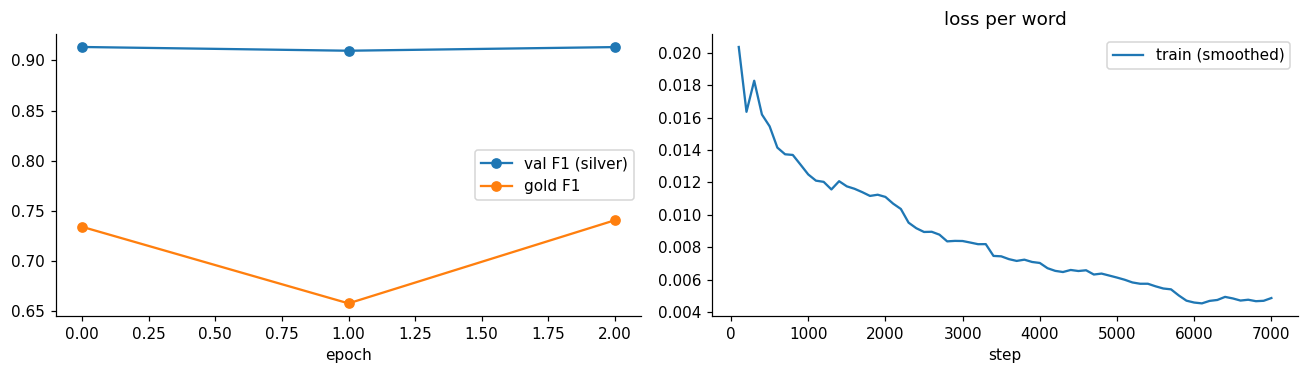

,val_f1,gold_f1,val_loss,gold_loss
epoch,,,,
0,0.913,0.734,0.008,0.070
1,0.910,0.658,0.009,0.084
2,0.913,0.741,0.009,0.108


In [13]:
log = pd.read_csv(ARTIFACTS / CFG["run_name"] / "logs" / "metrics.csv")
epochs = log.dropna(subset=["val_f1"]).groupby("epoch")[["val_f1", "gold_f1", "val_loss", "gold_loss"]].last()
step = log.dropna(subset=["train_loss_step"])
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].plot(epochs.index, epochs.val_f1, marker="o", label="val F1 (silver)")
axes[0].plot(epochs.index, epochs.gold_f1, marker="o", label="gold F1")
axes[0].set_xlabel("epoch"), axes[0].legend()
axes[1].plot(step.step, step.train_loss_step.rolling(20, min_periods=1).mean(), label="train (smoothed)")
axes[1].set_xlabel("step"), axes[1].set_title("loss per word"), axes[1].legend()
plt.tight_layout()
plt.show()
epochs.round(3)

Learned CRF transitions (row = previous tag, column = next tag). `O → I-LOC` should be strongly negative.

In [14]:
crf_params = torch.load(ARTIFACTS / CFG["run_name"] / "crf.pt", weights_only=True)
pd.DataFrame(crf_params["trans"].numpy(), index=LABELS, columns=LABELS).round(2)

,O,B-LOC,I-LOC
O,0.76,0.46,-3.27
B-LOC,-1.36,-1.09,2.42
I-LOC,-1.54,-1.05,2.50


Gold errors, one row per error, with the text around it (`⏎` is a line break):
- `missed`: a gold location the model did not output (an FN);
- `extra`: a prediction that is not in the gold (an FP);
- `boundary`: the missed or extra string shares a word with a string on the other side, so the model found the place
  but cut it wrong (`вул. Солом'янська` vs `вул. Солом'янська, 28`). On this metric it costs an FP *and* an FN.

Strings are compared after `hard_processing`, like the metric does.

In [15]:
def gold_errors(corpus: Corpus, pred: list[list[str]], width: int = 50) -> pd.DataFrame:
    rows = []
    for i, (text, true, predicted) in enumerate(zip(corpus.texts, corpus.locations, pred)):
        t, p = {hard_processing(s): s for s in true}, {hard_processing(s): s for s in predicted}
        for kind, mine, other in (("missed", t, p), ("extra", p, t)):
            unmatched_other = [set(k.split()) for k in other.keys() - mine.keys()]
            for key in sorted(mine.keys() - other.keys()):
                s, at = mine[key], text.find(mine[key])  # strings are cut from the text, so `find` locates them
                context = text[max(0, at - width):at] + "[" + s + "]" + text[at + len(s):at + len(s) + width]
                boundary = any(set(key.split()) & o for o in unmatched_other)
                rows.append({"text": i, "error": f"boundary, {kind}" if boundary else kind, "string": s,
                             "context": " ".join(context.replace("\n", " ⏎ ").split())})
    return pd.DataFrame(rows, columns=["text", "error", "string", "context"])


gold_pred = decode(corpora["gold"], load_probs(CFG["run_name"], "gold"))
errors = gold_errors(corpora["gold"], gold_pred)
print(errors.error.value_counts().to_dict())
with pd.option_context("display.max_colwidth", 200, "display.max_rows", 200):
    display(errors)

{'extra': 17, 'missed': 2, 'boundary, missed': 1, 'boundary, extra': 1}


,text,error,string,context
0,1,missed,Проспект Бандери,"[Проспект Бандери] стоїть, як і пів міста… довго ще?? ⏎ ⏎ Життя🫶Оболонь"
1,2,missed,Біла Церква,⏎ Чорнобиль - 19 ⏎ Київ - 12 ⏎ Тетерів - 9 ⏎ Фастів - 11 ⏎ [Біла Церква] - 13 ⏎ Миронівка - 13 ⏎ Бориспіль - 13 ⏎ Яготин - 12 ⏎ Ба
2,5,extra,Україні,"ойним Силам України і таким чином наближати мир в [Україні] після нашої Перемоги, — Сергій Попко, начальник К"
3,6,extra,України,ачення Рустема Умерова на посаду міністра оборони [України]. ⏎ ⏎ Більше кадрових питань на цьому тижні не буде.
4,7,extra,Індустріальний міст,ДТП біля заїзду в ТЦ Аркадія ⏎ ⏎ 📍[Індустріальний міст]
5,9,"boundary, missed",Бучанском,"те массированной атаки врага ночью в Фастовском и [Бучанском] районах возникли пожары и разрушения жилых домов,"
6,9,"boundary, extra",Бучанском районах,"те массированной атаки врага ночью в Фастовском и [Бучанском районах] возникли пожары и разрушения жилых домов, возгора"
7,10,extra,Київ,Свої дії він не пояснив. Швидка працює на місці. ⏎ ⏎ [Київ] — пряма трансляція 👈 ⏎ Надіслати новину
8,11,extra,Києва,"ативники затримали грабіжника, повідомляє поліція [Києва]. ⏎ ⏎ Зловмисник, вибравши жертву спровокував конфлік"
9,17,extra,Місяць,Найяскравіший і найбільший [Місяць] 2023 року


## 8. Results log and submission
The run goes into the shared results log with its gold scores. The submission file is
`dl-a3-artifacts/<run_name>/submission.csv`: upload it on the Kaggle competition page by hand, then write the public
score into the log with `log_result(CFG, report, lb_public=...)`.

In [16]:
LB_PUBLIC = None  # the public score from Kaggle, after uploading submission.csv by hand

log_result(CFG, report, lb_public=LB_PUBLIC, notes="fasttext-bigru-crf")
print("submission:", ARTIFACTS / CFG["run_name"] / "submission.csv")
read_log().tail(10)

submission: /content/drive/MyDrive/dl-a3-artifacts/taras-bigru2-word-fasttext-crf-case-clean-uk500k-ru100k/submission.csv


,run_name,owner,point,description,cv_f1,cv_p,cv_r,es_f1,lb_public,notes
0,taras-bigru2-word-fasttext-crf-case-data2-uk500k-ru100k,taras,8,"BiGRU, 2 layers, word-level, fastText cc.uk.300 (cased, fine-tuned at 0.1x lr), case feature, CRF, AdamW; train_v2 (...",0.765432,0.632653,0.96875,0.915480,NaN,fasttext-bigru-crf
1,taras-bigru2-word-fasttext-crf-case-clean-uk500k-ru100k,taras,8,"BiGRU, 2 layers, word-level, fastText cc.uk.300 (cased, fine-tuned at 0.1x lr), case feature, CRF, AdamW; cleaned tr...",0.734177,0.617021,0.90625,0.913451,NaN,fasttext-bigru-crf
